# 3. Final model, gene stability and explainability

The final model is a GA run on all 30 samples. It is only used for interpretation (SHAP, heatmap);
the performance estimate comes from the nested CV in notebook 2.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load, symbols, name, RESULTS
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GRAY, RED = "#184E7D", "#B8B8B8", "#A4243B"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

expr, y, meta = load()
sym = symbols()

In [2]:
from src.deg import pool
from src.ga import GA
from src.validation import cached

genes = pool(expr, y)
final = cached("final_ga", lambda: dict(zip(["genes", "history"], GA(seed=42).run(expr[genes], y))))
chosen = final["genes"]
print(len(chosen), "genes:", ", ".join(name(g, sym) for g in chosen))

10 genes: PTGER3, CHI3L2, SFRP1, UPK1B, SBSPON, TAP1, FABP4, AQP11, IGKC, HELLPAR


In [3]:
def stability():
    runs = []
    for seed in range(10):
        picked, _ = GA(seed=seed).run(expr[genes], y)
        print(f"seed {seed}: {len(picked)} genes")
        runs.append(picked)
    return runs

runs = cached("stability", stability)
counts = pd.Series([g for r in runs for g in r]).value_counts()
counts[counts >= 5].rename(index=lambda g: name(g, sym)).to_frame("runs (of 10)")

,runs (of 10)
HELLPAR,10
AQP11,7


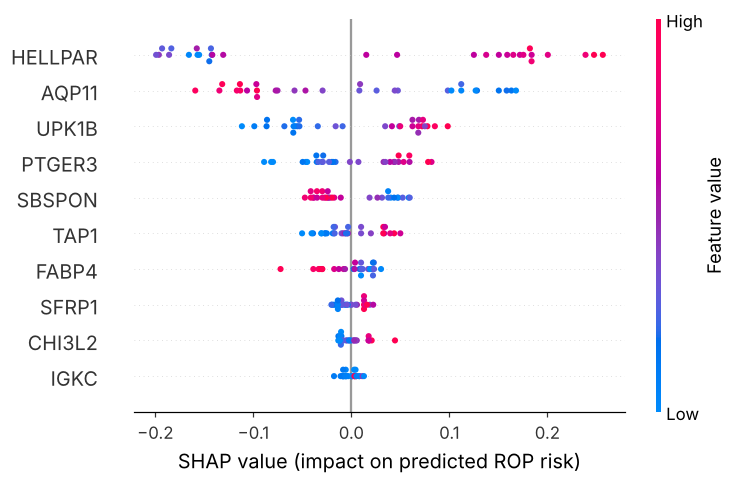

In [4]:
import shap
from sklearn.ensemble import RandomForestClassifier

X = expr[chosen].rename(columns=lambda g: name(g, sym))
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)
sv = shap.TreeExplainer(model).shap_values(X)
sv = sv[1] if isinstance(sv, list) else sv[:, :, 1]

shap.summary_plot(sv, X, show=False, plot_size=(7, 4.5))
plt.xlabel("SHAP value (impact on predicted ROP risk)")
plt.tight_layout()
plt.savefig(FIG / "shap_summary.png", dpi=200)

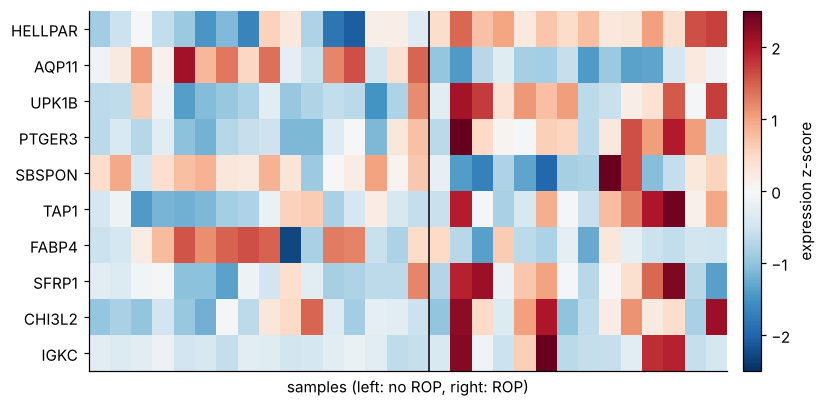

In [5]:
order = np.argsort(y, kind="stable")
z = ((X - X.mean()) / X.std()).iloc[order].T
z = z.loc[pd.Series(np.abs(sv).mean(0), index=X.columns).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 3.8))
im = ax.imshow(z, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
ax.axvline((y == 0).sum() - 0.5, c="k", lw=1)
ax.set(yticks=range(len(z)), yticklabels=z.index, xticks=[], xlabel="samples (left: no ROP, right: ROP)")
fig.colorbar(im, ax=ax, label="expression z-score", pad=0.02)
fig.tight_layout()
fig.savefig(FIG / "heatmap.png", dpi=200)

null AUC: 0.482 ± 0.156
real AUC (genes chosen on all data, optimistic): 1.000  p = 0.002
vs nested CV estimate 0.834: p = 0.012


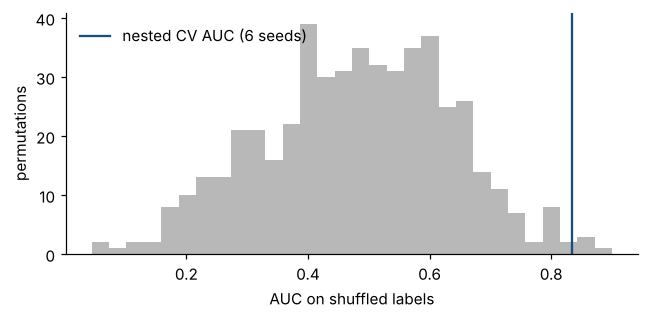

In [6]:
from src.validation import permutation_test

perm = cached("permutation", lambda: permutation_test(expr[chosen], y))
null = np.array(perm["null"])
p = lambda ref: (np.sum(null >= ref) + 1) / (len(null) + 1)
print(f"null AUC: {null.mean():.3f} ± {null.std():.3f}")
print(f"real AUC (genes chosen on all data, optimistic): {perm['real']:.3f}  p = {p(perm['real']):.3f}")
import json
nested = np.mean([f["auc"] for s in [42, 0, 1, 2, 3, 4] for f in json.loads((RESULTS / f"nested_ga_seed{s}.json").read_text())])
print(f"vs nested CV estimate {nested:.3f}: p = {p(nested):.3f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(null, bins=30, color=GRAY)
ax.axvline(nested, c=BLUE, label="nested CV AUC (6 seeds)")
ax.set(xlabel="AUC on shuffled labels", ylabel="permutations")
ax.legend(frameon=False)
fig.tight_layout()

Confounder check for the two stable genes: sex and maternal preeclampsia.

In [7]:
from scipy.stats import fisher_exact, mannwhitneyu

rows = []
for g in counts[counts >= 5].index:
    v = expr[g]
    rows.append({"gene": name(g, sym),
                 "p (male vs female)": mannwhitneyu(v[meta.sex == "M"], v[meta.sex == "F"]).pvalue,
                 "p (preeclampsia yes vs no)": mannwhitneyu(v[meta.preeclampsia], v[~meta.preeclampsia]).pvalue})
print("sex vs ROP, Fisher p =", round(fisher_exact(pd.crosstab(meta.sex, meta.rop))[1], 3))
print("preeclampsia vs ROP, Fisher p =", round(fisher_exact(pd.crosstab(meta.preeclampsia, meta.rop))[1], 3))
pd.DataFrame(rows).set_index("gene").round(3)

sex vs ROP, Fisher p = 0.73
preeclampsia vs ROP, Fisher p = 0.715


,p (male vs female),p (preeclampsia yes vs no)
gene,,
HELLPAR,0.467,0.455
AQP11,0.177,0.455
